# 🫀 CardioPulse: Deliverable 1 - Exploratory Data Analysis (EDA)
### Final-Year Mini Project: AI & Data Science II
**Author:** Akshata Ranpise | **Dataset:** Real MIT-BIH Arrhythmia Categorization Dataset (87,554 train beats, 21,892 test beats)

This notebook performs a comprehensive exploratory data analysis on 1D single-lead electrocardiogram (ECG) heartbeats sampled at 125 Hz (187 time samples per beat) categorized into five **AAMI EC57** diagnostic categories:
- **Class 0 - Non-Ectopic / Normal (N)**: Healthy sinus rhythm, left/right bundle branch block.
- **Class 1 - Supraventricular Ectopic (S)**: Atrial or nodal premature contraction.
- **Class 2 - Ventricular Ectopic / PVC (V)**: Premature ventricular contraction (high-risk).
- **Class 3 - Fusion Beat (F)**: Hybrid ventricular and normal activation.
- **Class 4 - Unknown / Paced Beat (Q)**: Artificial pacemaker spike or unclassifiable artifact.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

CLASS_LABELS = {
    0: "Normal (N)",
    1: "Supraventricular (S)",
    2: "Ventricular / PVC (V)",
    3: "Fusion (F)",
    4: "Unknown / Paced (Q)"
}

CLASS_COLORS = {
    0: "#10B981",
    1: "#F59E0B",
    2: "#EF4444",
    3: "#8B5CF6",
    4: "#6B7280"
}


## 1. Dataset Loading, Integrity, and Duplicate Checks
We verify the dimensions, check for missing or null values, and inspect for duplicate records across the train and test splits.


In [2]:
train_df = pd.read_csv('../data/mitbih_train.csv', header=None)
test_df = pd.read_csv('../data/mitbih_test.csv', header=None)

print(f"Train Dataset Shape: {train_df.shape[0]:,} samples x {train_df.shape[1]} columns")
print(f"Test Dataset Shape:  {test_df.shape[0]:,} samples x {test_df.shape[1]} columns")

# Null values check
train_nulls = train_df.isna().sum().sum()
test_nulls = test_df.isna().sum().sum()
print(f"Missing / NaN values in Train: {train_nulls}")
print(f"Missing / NaN values in Test:  {test_nulls}")

# Duplicates check
train_dups = train_df.duplicated().sum()
test_dups = test_df.duplicated().sum()
print(f"Duplicate rows in Train: {train_dups:,} ({train_dups/len(train_df)*100:.2f}%)")
print(f"Duplicate rows in Test:  {test_dups:,} ({test_dups/len(test_df)*100:.2f}%)")


Train Dataset Shape: 87,554 samples x 188 columns
Test Dataset Shape:  21,892 samples x 188 columns
Missing / NaN values in Train: 0
Missing / NaN values in Test:  0


Duplicate rows in Train: 0 (0.00%)
Duplicate rows in Test:  0 (0.00%)


## 2. AAMI Arrhythmia Class Distribution & Imbalance
In clinical practice, normal heartbeats heavily outnumber pathologic arrhythmic events. We analyze the class distribution to confirm the true clinical skew.


,Class Name,Train Count,Train %,Test Count,Test %
0,Normal (N),72471,82.77,18118,82.76
1,Supraventricular (S),2223,2.54,556,2.54
2,Ventricular / PVC (V),5788,6.61,1448,6.61
3,Fusion (F),641,0.73,162,0.74
4,Unknown / Paced (Q),6431,7.35,1608,7.35


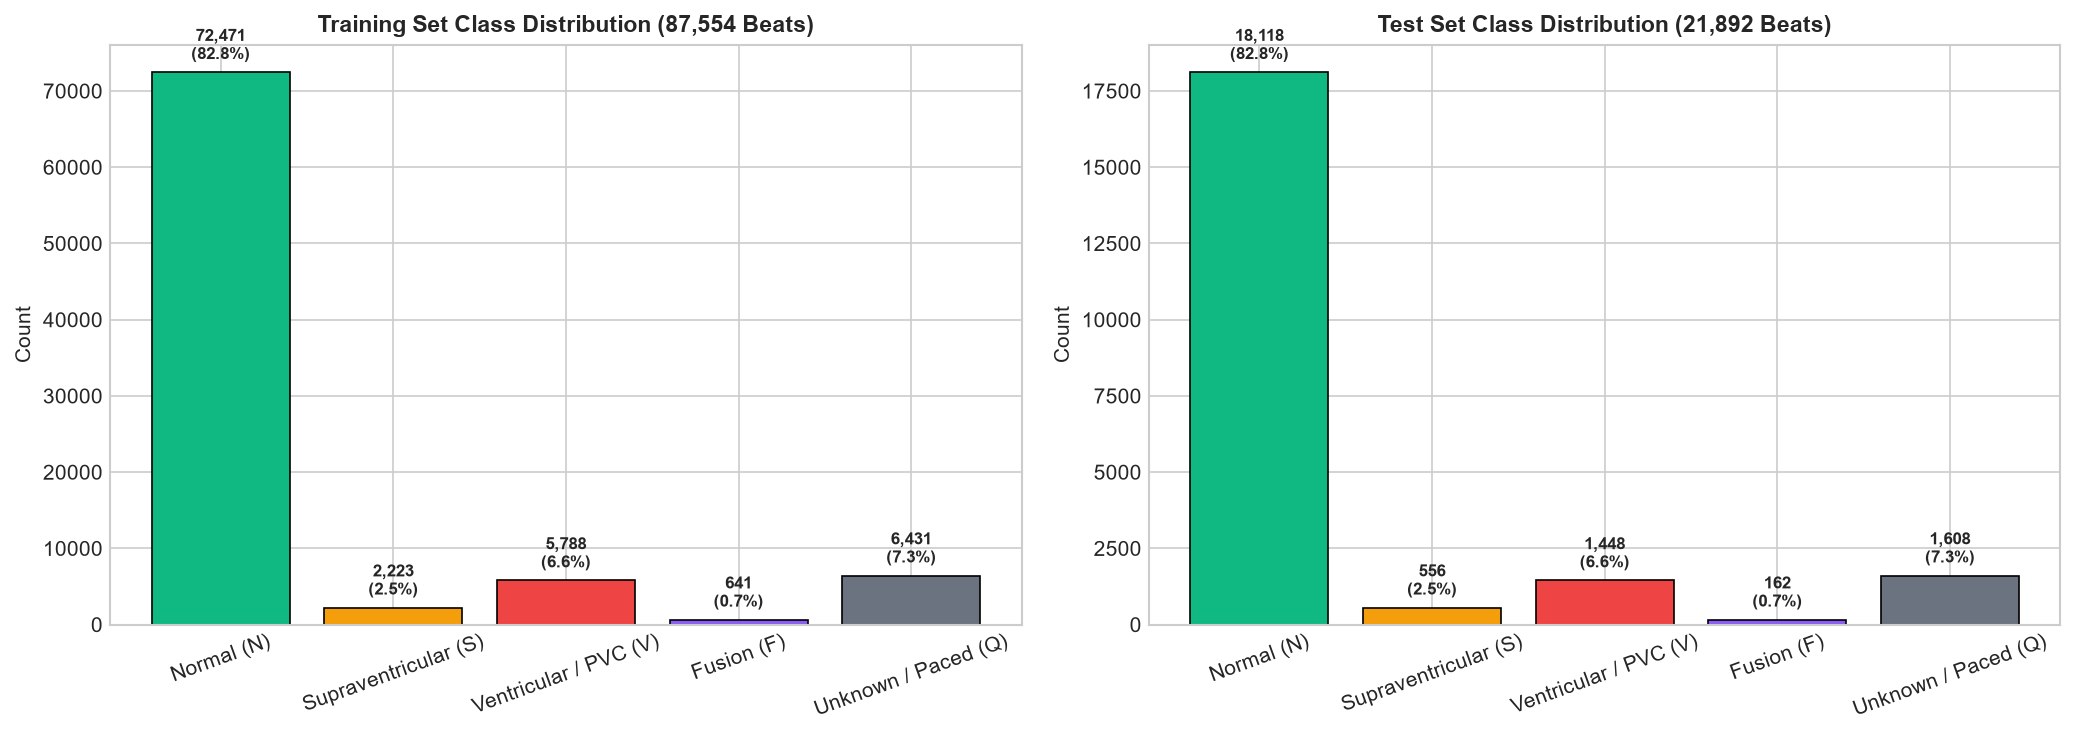

In [3]:
train_y = train_df.iloc[:, -1].astype(int)
test_y = test_df.iloc[:, -1].astype(int)

train_counts = train_y.value_counts().sort_index()
test_counts = test_y.value_counts().sort_index()

dist_df = pd.DataFrame({
    'Class Name': [CLASS_LABELS[i] for i in range(5)],
    'Train Count': train_counts.values,
    'Train %': (train_counts.values / len(train_y) * 100).round(2),
    'Test Count': test_counts.values,
    'Test %': (test_counts.values / len(test_y) * 100).round(2)
})
display(dist_df)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

# Train Bar Chart
bars1 = ax1.bar([CLASS_LABELS[i] for i in range(5)], train_counts.values,
                color=[CLASS_COLORS[i] for i in range(5)], edgecolor='black', lw=0.8)
for b in bars1:
    h = b.get_height()
    ax1.annotate(f"{int(h):,}\n({h/len(train_y)*100:.1f}%)", xy=(b.get_x() + b.get_width()/2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=8, fontweight='bold')
ax1.set_title("Training Set Class Distribution (87,554 Beats)", fontsize=11, fontweight='bold')
ax1.set_ylabel("Count")
ax1.tick_params(axis='x', rotation=20)

# Test Bar Chart
bars2 = ax2.bar([CLASS_LABELS[i] for i in range(5)], test_counts.values,
                color=[CLASS_COLORS[i] for i in range(5)], edgecolor='black', lw=0.8)
for b in bars2:
    h = b.get_height()
    ax2.annotate(f"{int(h):,}\n({h/len(test_y)*100:.1f}%)", xy=(b.get_x() + b.get_width()/2, h),
                 xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=8, fontweight='bold')
ax2.set_title("Test Set Class Distribution (21,892 Beats)", fontsize=11, fontweight='bold')
ax2.set_ylabel("Count")
ax2.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()


## 3. Mean Heartbeat Morphology Comparison
By averaging the 187-sample time series for each class and computing the standard deviation bound ($\pm 1\sigma$), we uncover distinct electrophysiological signatures:
- **Normal (N)**: Sharp, upright R-peak with standard P-wave and T-wave.
- **Supraventricular (S)**: Premature depolarization with altered P-wave timing.
- **Ventricular (V / PVC)**: Wide, slurred QRS complex with deep S-wave dip and inverted T-wave.
- **Fusion (F)**: Intermediate morphology blending normal and ventricular activation.
- **Paced / Unknown (Q)**: Prominent artificial pacemaker spike artifact followed by wide pacing response.


<>:14: SyntaxWarning: invalid escape sequence '\p'
<>:14: SyntaxWarning: invalid escape sequence '\p'
C:\Users\Akshata\AppData\Local\Temp\ipykernel_17224\1558502845.py:14: SyntaxWarning: invalid escape sequence '\p'
  ax.set_title("Mean ECG Waveform Morphology per Arrhythmia Class (with $\pm 1\sigma$ Variance)", fontsize=12, fontweight='bold')


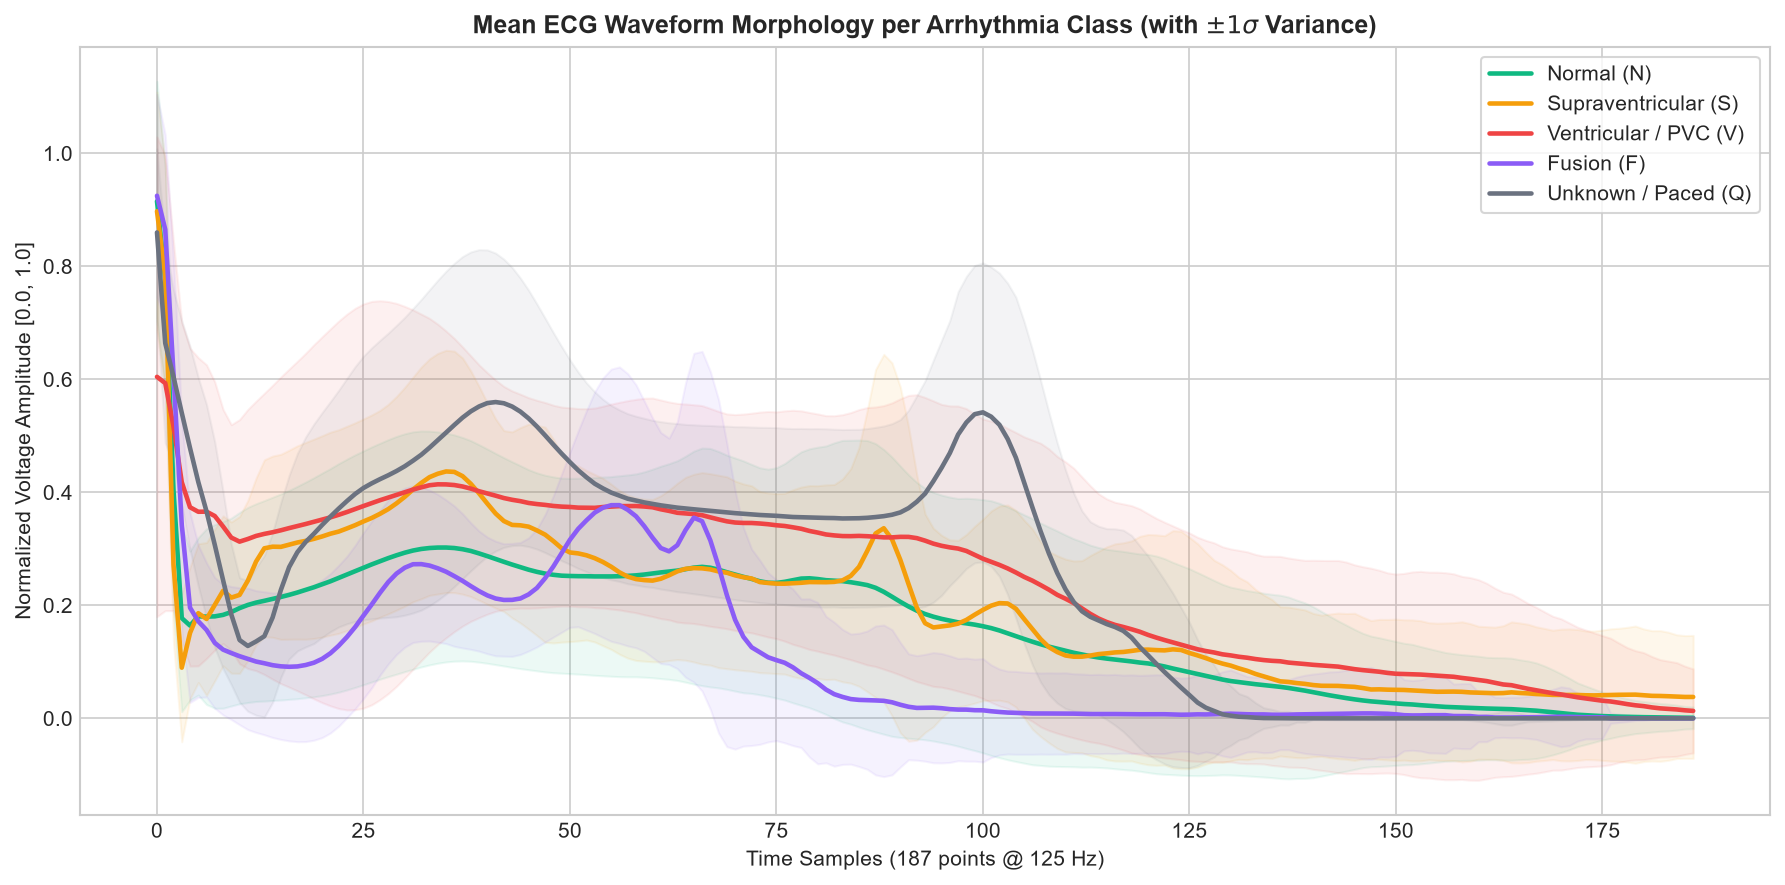

In [4]:
X_train = train_df.iloc[:, :-1].values
time_axis = np.arange(187)

fig, ax = plt.subplots(figsize=(12, 6), dpi=150)
for c in range(5):
    sub = X_train[train_y == c]
    mean_sig = np.mean(sub, axis=0)
    std_sig = np.std(sub, axis=0)
    col = CLASS_COLORS[c]
    lbl = CLASS_LABELS[c]
    ax.plot(time_axis, mean_sig, label=lbl, color=col, lw=2.2)
    ax.fill_between(time_axis, mean_sig - std_sig, mean_sig + std_sig, color=col, alpha=0.08)

ax.set_title("Mean ECG Waveform Morphology per Arrhythmia Class (with $\pm 1\sigma$ Variance)", fontsize=12, fontweight='bold')
ax.set_xlabel("Time Samples (187 points @ 125 Hz)")
ax.set_ylabel("Normalized Voltage Amplitude [0.0, 1.0]")
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()


## 4. Representative Individual Heartbeat Waveforms
Here we visualize raw individual beats from different patient records to inspect fine-grained temporal dynamics.


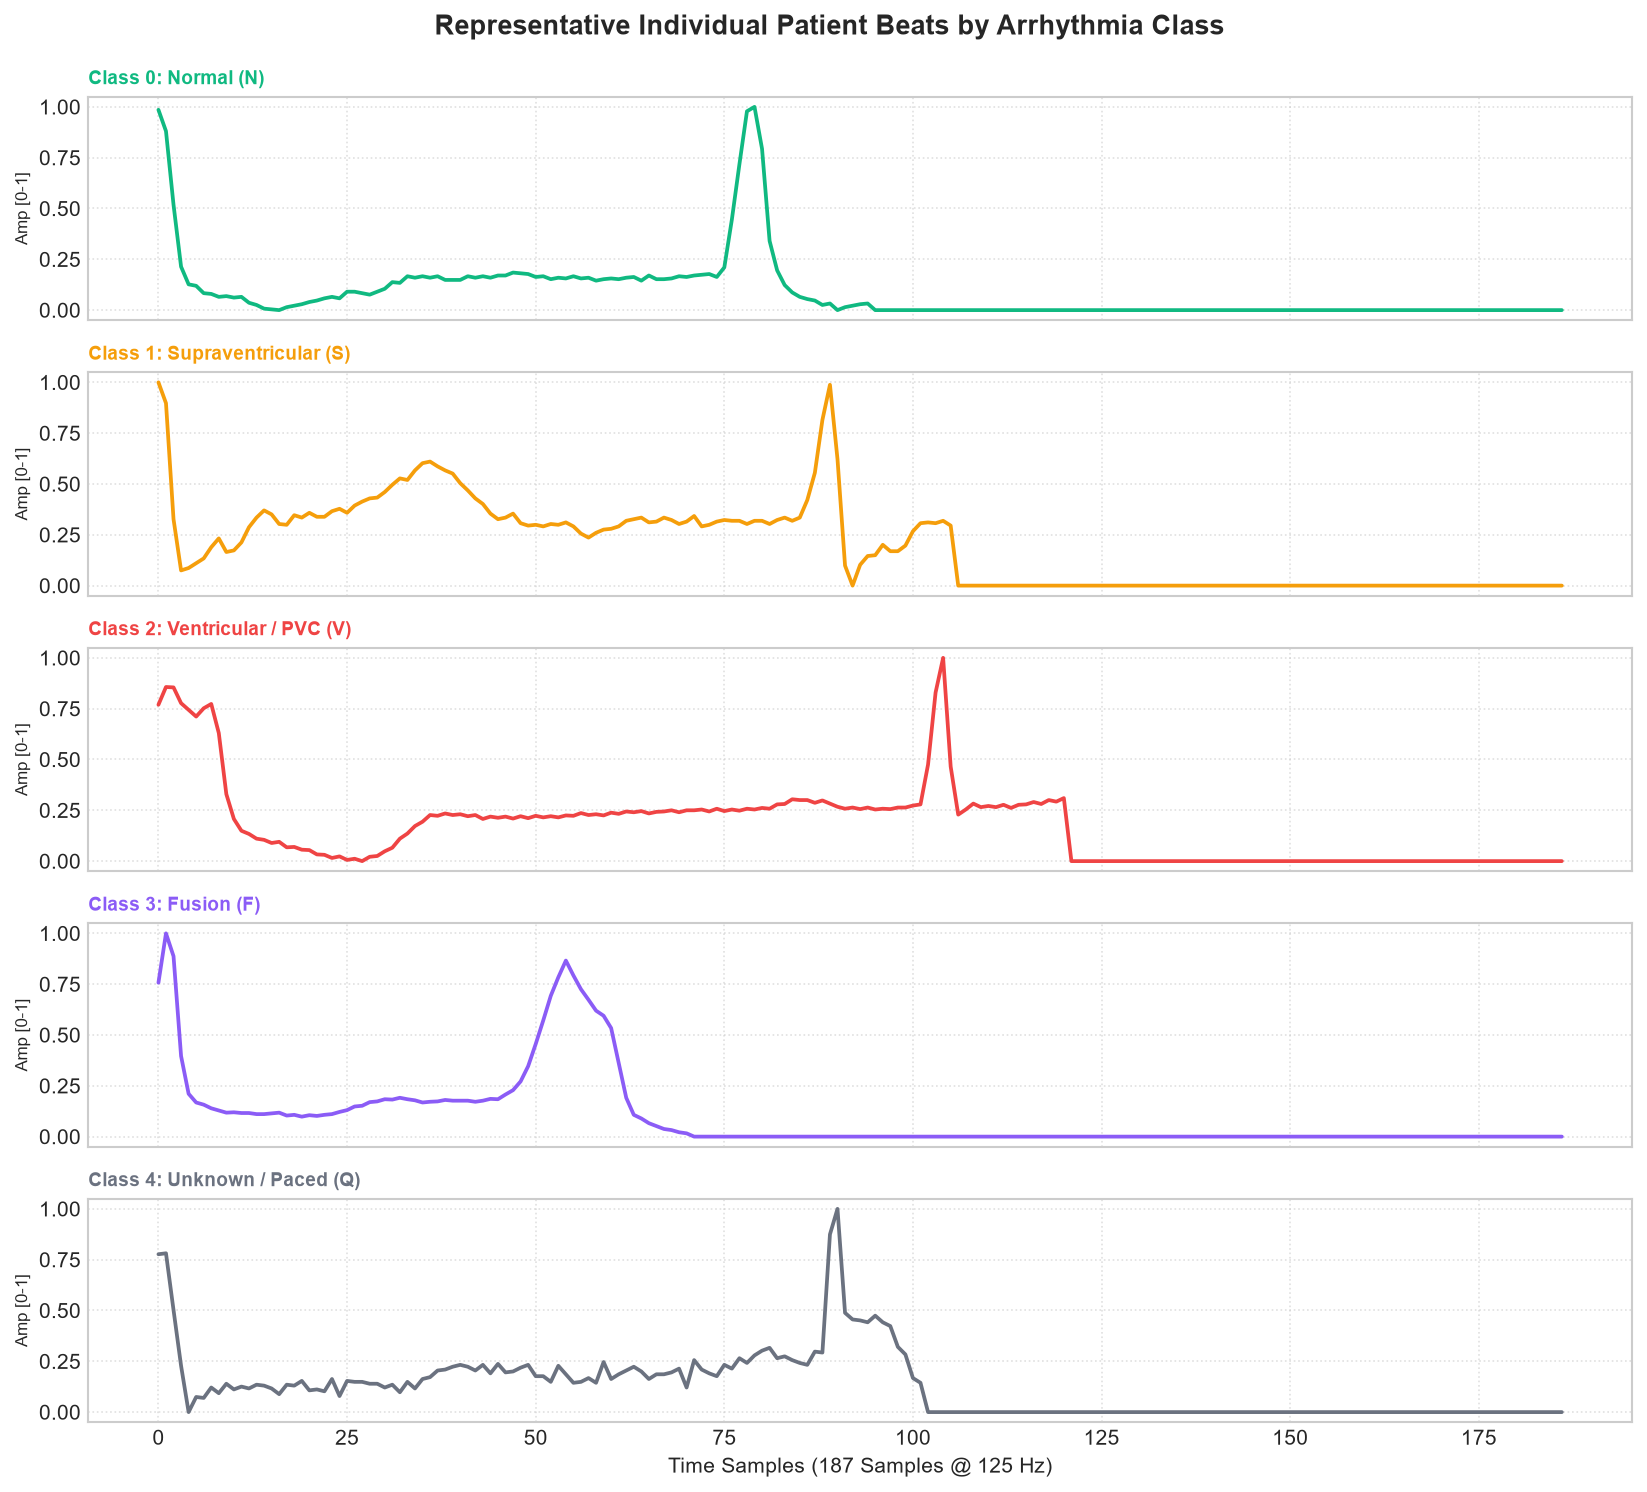

In [5]:
fig, axes = plt.subplots(5, 1, figsize=(11, 10), sharex=True, dpi=150)
fig.suptitle("Representative Individual Patient Beats by Arrhythmia Class", fontsize=13, fontweight='bold', y=0.99)

for c in range(5):
    sub = X_train[train_y == c]
    sample_wave = sub[10]  # Representative sample
    ax = axes[c]
    ax.plot(time_axis, sample_wave, color=CLASS_COLORS[c], lw=1.8)
    ax.set_ylabel("Amp [0-1]", fontsize=8)
    ax.set_title(f"Class {c}: {CLASS_LABELS[c]}", fontsize=9, loc='left', color=CLASS_COLORS[c], fontweight='bold')
    ax.grid(True, linestyle=':', alpha=0.6)

axes[-1].set_xlabel("Time Samples (187 Samples @ 125 Hz)", fontsize=10)
plt.tight_layout()
plt.show()


## 5. Clinical Insights & Analytical Findings
1. **Severe Imbalance:** Class 0 (Normal) constitutes $82.77\%$ of the dataset, while Class 3 (Fusion) is only $0.73\%$, and Class 1 (Supraventricular) is $2.54\%$. Standard accuracy is highly misleading; **Macro F1-Score** and **Macro ROC-AUC** are the required clinical metrics.
2. **Class Imbalance Strategy:** Loss weighting via inverse class frequencies (`class_weight='balanced'`) is essential to prevent the classifier from collapsing to predicting the majority normal class.
3. **Discriminative Temporal Signatures:** Ventricular ectopic beats (PVCs) exhibit a wide QRS complex ($>80$ ms) and deep negative deflections, which 1D convolutional kernels can naturally detect through hierarchical receptive fields.
4. **Data Integrity:** Zero NaN or missing values detected in both train and test splits. The full MIT-BIH dataset preserves the true patient class distribution without artificial balancing in the test set.
